# DESI DR1 quasars: reading the PyQSOFit output files

Every spectrum in the VAC has its own PyQSOFit output file, `op_<OBJID>.fits.gz`, where
`OBJID = SURVEY-PROGRAM-HEALPIX-TARGETID`. This notebook explains the structure of these files and shows how to
- read the processed spectrum (and the host-galaxy decomposition at $z<1$),
- rebuild the continuum and emission-line models from the best-fit parameters,
- recompute the line properties listed in the VAC, with their Monte Carlo uncertainties,
- read the local fits of narrow/coronal lines,
- make a QA plot of the fit.

Three example files are included in `download/`:
- `op_main-dark-36522-39627334138987461.fits.gz`: a $z=2.35$ quasar, UV lines (Ly$\alpha$ to MgII)
- `op_sv1-dark-6872-39633211269056848.fits.gz`: a $z=0.32$ quasar with host-galaxy decomposition and optical lines (H$\delta$ to H$\alpha$)
- `op_main-dark-19046-39627784217169648.fits.gz`: a $z=0.37$ quasar with strong narrow and coronal lines ([OII], [NeV], [FeX])

The functions used here are defined in `qsofunc.py`.

In [1]:
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import warnings
warnings.filterwarnings("ignore")

from qsofunc import *
set_mpl_style()

# 1. File structure

Each file has three binary-table extensions:

| Extension | Rows | Content |
| --- | --- | --- |
| 1 | 1 | best-fit parameters: object info, continuum, host decomposition, line complexes, Gaussian components, local fits |
| 2 | 10 | the same fitted parameters (suffix `_MC`) for each of the 10 Monte Carlo trials, used for the uncertainties |
| 3 | N pixels | the processed spectrum (and host decomposition) |

In [2]:
objid = 'main-dark-36522-39627334138987461'
op_file = f'./download/op_{objid}.fits.gz'

fits.info(op_file)
op_data, op_data_MC, op_data_spec = read_op(op_file)
# equivalent to
# op_data = fits.getdata(op_file, 1); op_data_MC = fits.getdata(op_file, 2); op_data_spec = fits.getdata(op_file, 3)

Filename: ./download/op_main-dark-36522-39627334138987461.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU    494   1R x 243C   [8A, K, K, K, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, 8A, K, D, D, D, K, K, K, 8A, K, D, D, D, K, K, K, 8A, K, D, D, D, K, K, K, 8A, K, D, D, D, K, K, K, 8A, K, D, D, D, K, K, K, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D]   
  2                1 BinTabl

## Extension 1: best-fit parameters

The columns come in groups:

| Columns | Description |
| --- | --- |
| `ra`, `dec`, `redshift`, `SN_ratio_conti`, `EBV` | coordinates, input redshift (`Z_FIT` in the VAC), median S/N in the continuum windows, Galactic $E(B-V)$ |
| `PL_norm`, `PL_slope` | power law $f = a\,(\lambda/3000\,{\rm \AA})^{\alpha}$ |
| `conti_a_0`, `conti_a_1`, `conti_a_2` | polynomial $\sum_i (a_i/10^6)\,(\lambda-3000)^{i+1}$ |
| `Fe_uv_norm/FWHM/shift`, `Fe_op_norm/FWHM/shift` | UV and optical FeII templates: normalization, FWHM (km/s), wavelength shift |
| `Blamer_norm`, `Balmer_Te`, `Balmer_Tau` | Balmer continuum (not fitted in this work: `Blamer_norm` = 0) |
| `L1350` ... `L5100` | continuum luminosity $\log \lambda L_\lambda$ (erg/s), -1 if not covered |
| `Fe_flux_4435_4685` | optical FeII flux in 4435-4685 Å |
| `SN_host`, `frac_host_4200`, `frac_host_5100`, `Dn4000`, `gal_par_*`, `qso_par_*`, ... | host decomposition (only $z<1$, see below) |
| `<k>_complex_name`, `<k>_line_status`, `<k>_line_min_chi2`, `<k>_line_bic`, `<k>_line_red_chi2`, `<k>_niter`, `<k>_ndof`, `<k>_npix` | summary of the fit of the $k$-th line complex |
| `<line>_<n>_scale`, `<line>_<n>_centerwave`, `<line>_<n>_sigma` | Gaussian component $n$ of a line: peak flux density, $\ln(\lambda_c/{\rm \AA})$, $\sigma$ in $\ln\lambda$ |
| `loc_<k>_*`, `<comp>_PL_norm/slope`, `<line>_1_*`, `<line>_1_detect` | local fits of narrow / coronal lines (see Section 5) |

Every fitted parameter `X` has an uncertainty `X_err` (half of the 16-84 percentile range of the MC trials).
All fits are done in the rest frame, on the Galactic-dereddened spectrum, with fluxes in units of
$10^{-17}\,{\rm erg\,s^{-1}\,cm^{-2}\,\AA^{-1}}$.

In [3]:
for name in ['ra', 'dec', 'redshift', 'SN_ratio_conti', 'EBV']:
    print(f'{name:16s} {op_data[name][0]}')
print(len(op_data.names), 'columns in extension 1')

ra               22.989345331428684
dec              -19.06538134636261
redshift         2.3541899553657344
SN_ratio_conti   7.485875893413138
EBV              0.01197076684167249
243 columns in extension 1


## Extension 3: the processed spectrum

The spectrum is
- cleaned of bad pixels,
- corrected for Galactic extinction (SFD map, Cardelli et al. 1989 curve with $R_V=3.1$, rescaled following Schlafly & Finkbeiner 2011),
- shifted to the rest frame: wavelength divided by $(1+z)$ and flux multiplied by $(1+z)$, with $z$ = `redshift`.

| Column | Description |
| --- | --- |
| `wave_prereduced`, `flux_prereduced`, `err_prereduced` | rest-frame wavelength, flux density and error |
| `wave_conti_rej_abs` | pixels rejected as absorption in the continuum fit |
| `wave_line_rej_abs` | pixels rejected as absorption in the line fits |
| `wave_hostfree`, `flux_hostfree`, `err_hostfree` | host-subtracted spectrum (only with host decomposition) |
| `flux_pca_qso`, `flux_pca_host` | quasar and host-galaxy PCA models (only with host decomposition) |

Shorter columns are padded with zeros to the length of the table; `get_spectrum` removes the padding.

['wave_prereduced', 'flux_prereduced', 'err_prereduced', 'wave_conti_rej_abs', 'wave_line_rej_abs']


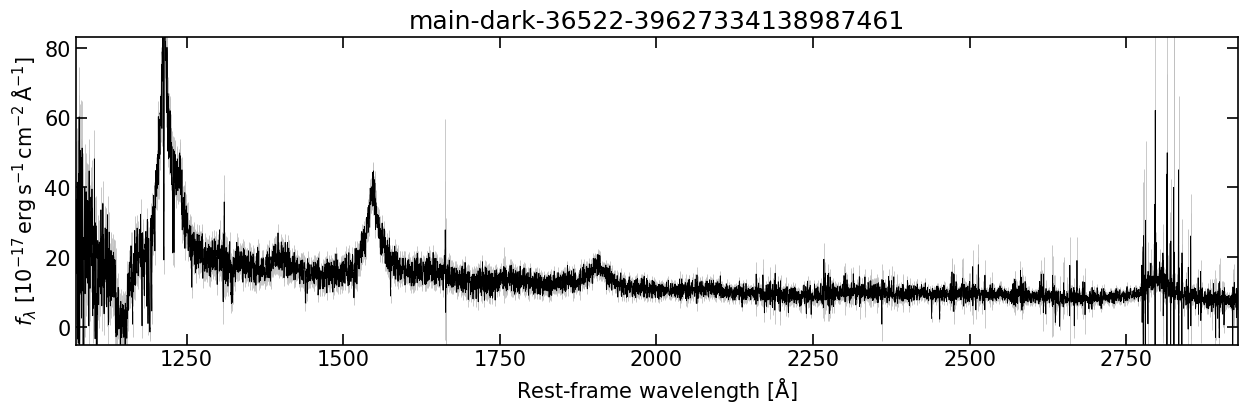

In [4]:
print(op_data_spec.names)
wave, flux, err = get_spectrum(op_data_spec)

fig, ax = plt.subplots(1, 1, figsize=(15, 4))
ax.errorbar(wave, flux, yerr=err, color='k', ecolor='silver', lw=0.6)
ax.set_title(objid)
ax.set_xlabel(r'Rest-frame wavelength [$\rm \AA$]')
ax.set_ylabel(r'$f_{\lambda}$ [$\rm 10^{-17}\,erg\,s^{-1}\,cm^{-2}\,\AA^{-1}$]')
ax.set_xlim(wave.min(), wave.max())
ax.set_ylim(-5, 1.3*np.percentile(flux, 99.5))
plt.show()

# 2. Continuum model

$$f_{\rm conti}(\lambda) = f_{\rm PL} + f_{\rm poly} + f_{\rm FeII,UV} + f_{\rm FeII,opt}$$
with
$$f_{\rm PL} = a\,(\lambda/3000\,{\rm \AA})^{\alpha},\qquad f_{\rm poly} = \sum_{i=0}^{2} \frac{a_i}{10^6}\,(\lambda-3000\,{\rm \AA})^{i+1},$$
$$f_{\rm FeII} = c_0\,F_{\rm FeII}(\lambda(1+c_2);\ {\rm FWHM}=c_1).$$

The continuum is fitted in the line-free windows listed in extension `CONTI_WINDOWS` of `qsopar.fits`.

In [5]:
conti_para = get_conti_para(op_data)          # order: CONTI_KEYWORD
for name, val in zip(CONTI_KEYWORD, conti_para):
    print(f'{name:12s} {val:12.4f} +- {op_data[name+"_err"][0]:.4f}')

for name in ['L1350', 'L1700', 'L2500', 'L3000', 'L4200', 'L5100']:
    print(f'LOG{name}: {op_data[name][0]:.3f} +- {op_data[name+"_err"][0]:.3f}')

PL_norm            6.2963 +- 0.2430
PL_slope          -0.3157 +- 0.0033
conti_a_0      -3540.1350 +- 809.9035
conti_a_1         -1.9534 +- 1.1092
conti_a_2         -0.0017 +- 0.0004
Fe_uv_norm         0.2187 +- 0.0152
Fe_uv_FWHM      5188.9240 +- 550.8690
Fe_uv_shift       -0.0038 +- 0.0009
Fe_op_norm         0.0000 +- 0.0000
Fe_op_FWHM      3000.0000 +- 0.0000
Fe_op_shift        0.0000 +- 0.0000
LOGL1350: 45.976 +- 0.003
LOGL1700: 45.964 +- 0.002
LOGL2500: 45.943 +- 0.004
LOGL3000: -1.000 +- -1.000
LOGL4200: -1.000 +- -1.000
LOGL5100: -1.000 +- -1.000


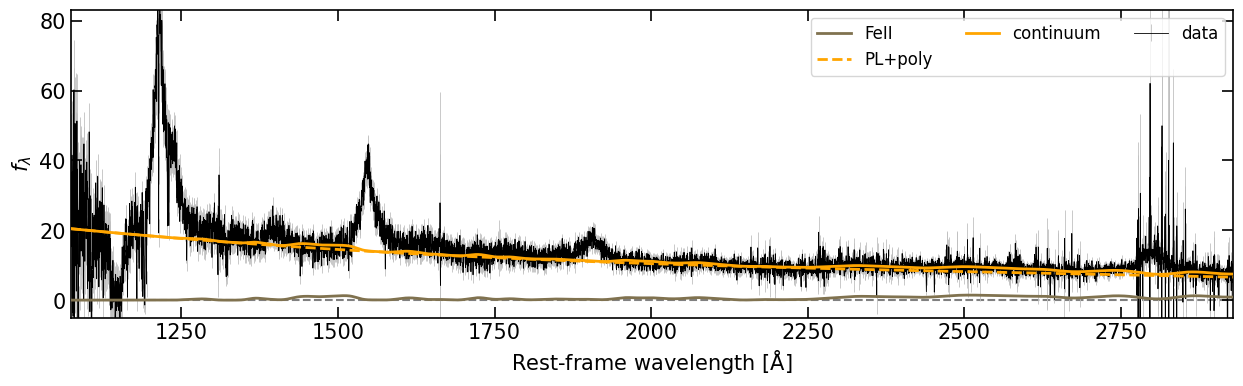

In [6]:
conti_model = continuum_all(wave, conti_para)
pl_poly_model = continuum_PL_poly(wave, conti_para)
fe_model = FeII_uv_Conti(wave, conti_para[5:8]) + FeII_opt_Conti(wave, conti_para[8:])

fig, ax = plt.subplots(1, 1, figsize=(15, 4))
ax.errorbar(wave, flux, yerr=err, color='k', ecolor='silver', lw=0.6, label='data', zorder=1)
ax.plot(wave, fe_model, c='#80724f', lw=2, label='FeII', zorder=3)
ax.plot(wave, pl_poly_model, c='orange', ls='--', lw=2, label='PL+poly', zorder=4)
ax.plot(wave, conti_model, c='orange', lw=2, label='continuum', zorder=5)
ax.axhline(0, ls='--', c='grey', zorder=0)
ax.legend(loc='upper right', ncol=3, fontsize=12)
ax.set_xlabel(r'Rest-frame wavelength [$\rm \AA$]')
ax.set_ylabel(r'$f_{\lambda}$')
ax.set_xlim(wave.min(), wave.max())
ax.set_ylim(-5, 1.3*np.percentile(flux, 99.5))
plt.show()

# 3. Emission-line model

After subtracting the continuum, the lines are fitted complex by complex (Ly$\alpha$, SiIV, CIV, CIII], MgII,
H$\gamma$+H$\delta$, H$\beta$, H$\alpha$) with multiple Gaussians in $\ln\lambda$. The line priors are in the
`LINE_PRIORS` extension of `qsopar.fits`. The complexes fitted for this object and their reduced $\chi^2$:

In [7]:
for n in op_data.names:
    if n.endswith('_complex_name') and not n.startswith('loc_'):
        k = n[:-len('_complex_name')]
        print(f'{k}: {op_data[n][0]:6s} npix={op_data[k+"_npix"][0]:5d}  red_chi2={op_data[k+"_line_red_chi2"][0]:.2f}  '
              f'status={op_data[k+"_line_status"][0]}')

1: Lya    npix=  494  red_chi2=1.16  status=1
2: SiIV   npix=  621  red_chi2=0.77  status=1
3: CIV    npix=  813  red_chi2=0.99  status=1
4: CIII   npix= 1050  red_chi2=0.83  status=1
5: MgII   npix=  780  red_chi2=0.89  status=1


In [8]:
qsopar = fits.getdata('qsopar.fits', 'LINE_PRIORS')
print('line priors in qsopar.fits:', list(qsopar['linename']))
print()
print('Gaussian components saved for this object:')
for g in gauss_names(op_data):
    print(f'  {g:15s} scale={op_data[g+"_scale"][0]:9.3f}  center={np.exp(op_data[g+"_centerwave"][0]):8.2f} A  '
          f'sigma={op_data[g+"_sigma"][0]*C_KMS:7.1f} km/s')

line priors in qsopar.fits: ['Halpha_br', 'Halpha_na', 'NII6549', 'NII6585', 'SII6718', 'SII6732', 'Hbeta_br', 'Hbeta_na', 'OIII4959c', 'OIII5007c', 'OIII4959w', 'OIII5007w', 'HeII4687_br', 'HeII4687_na', 'Hgamma_br', 'Hgamma_na', 'Hdelta_br', 'Hdelta_na', 'MgII_br', 'MgII_na', 'CIII_br', 'SiIII1892', 'AlIII1857', 'SiII1816', 'NIII1750', 'NIV1718', 'CIV_br', 'HeII1640', 'OIII1663', 'HeII1640_br', 'OIII1663_br', 'SiIV_OIV1', 'SiIV_OIV2', 'CII1335', 'OI1304', 'Lya_br', 'NV1240']

Gaussian components saved for this object:
  Lya_br_1        scale=   13.593  center= 1215.09 A  sigma=  299.8 km/s
  Lya_br_2        scale=   12.036  center= 1226.95 A  sigma= 7136.6 km/s
  Lya_br_3        scale=   45.419  center= 1214.22 A  sigma= 1905.4 km/s
  NV1240_1        scale=   13.910  center= 1237.24 A  sigma= 1446.9 km/s
  SiIV_OIV1_1     scale=    0.827  center= 1403.94 A  sigma= 2964.9 km/s
  SiIV_OIV2_1     scale=    3.510  center= 1398.63 A  sigma= 2964.9 km/s
  CII1335_1       scale=    2.043  c

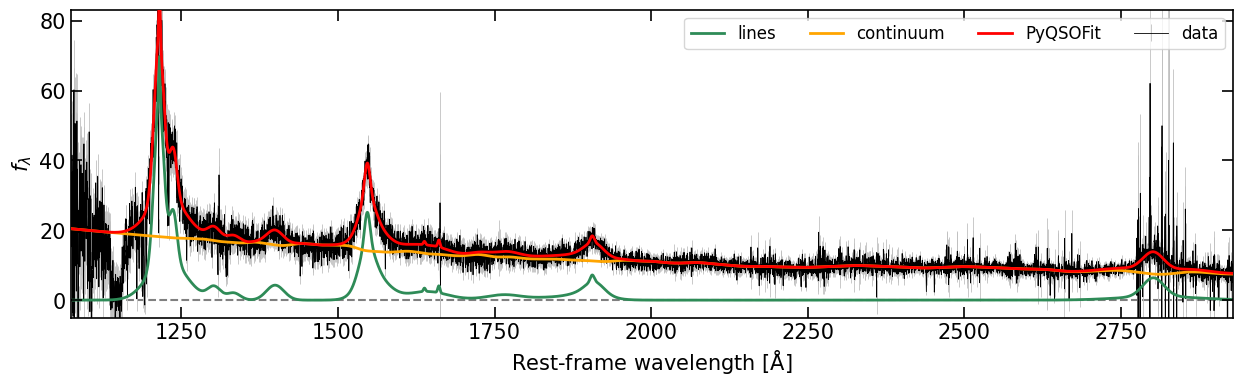

In [9]:
# total line model on the spectrum grid
line_flux = line_model(op_data, wave)

fig, ax = plt.subplots(1, 1, figsize=(15, 4))
ax.errorbar(wave, flux, yerr=err, color='k', ecolor='silver', lw=0.6, label='data', zorder=1)
ax.plot(wave, line_flux, c='seagreen', lw=2, label='lines', zorder=2)
ax.plot(wave, conti_model, c='orange', lw=2, label='continuum', zorder=3)
ax.plot(wave, conti_model+line_flux, c='red', lw=2, label='PyQSOFit', zorder=4)
ax.axhline(0, ls='--', c='grey', zorder=0)
ax.legend(loc='upper right', ncol=4, fontsize=12)
ax.set_xlabel(r'Rest-frame wavelength [$\rm \AA$]')
ax.set_ylabel(r'$f_{\lambda}$')
ax.set_xlim(wave.min(), wave.max())
ax.set_ylim(-5, 1.3*np.percentile(flux, 99.5))
plt.show()

## Line properties

The VAC line columns are built by summing the Gaussian components listed in `LINE_LIST` (e.g. `CIV` = `CIV_br_1-3`,
`MGII_BR` = `MgII_br_1-2`) and measuring on the summed profile:

`[peak wavelength (A), flux (1e-17 erg/s/cm2), log L (erg/s), FWHM (km/s), rest-frame EW (A), 50% flux centroid wavelength (A)]`.

The uncertainties are half of the 16-84 percentile range of the same quantities measured on the 10 MC trials in
extension 2. `get_line_prop` returns both and reproduces the VAC values.

In [10]:
print(list(LINE_LIST))

['HALPHA', 'HALPHA_BR', 'HALPHA_NA', 'NII6549', 'NII6585', 'SII6718', 'SII6732', 'HBETA', 'HBETA_BR', 'HBETA_NA', 'HEII4687', 'HEII4687_BR', 'OIII5007', 'OIII5007C', 'OIII4960', 'OIII4960C', 'HGAMMA', 'HDELTA', 'MGII', 'MGII_BR', 'CIII_BR', 'SIIII1892', 'ALIII1857', 'NIII1750', 'CIV', 'HEII1640', 'HEII1640_BR', 'SIIV_OIV', 'OI1304', 'LYA', 'NV1240']


In [11]:
civ, civ_err = get_line_prop('CIV', op_data, op_data_MC, op_data_spec)
mgii, mgii_err = get_line_prop('MGII_BR', op_data, op_data_MC, op_data_spec)

CIV
  Peak wavelength      1546.919 +-     0.233  [A]
  Flux                  790.850 +-    17.817  [1e-17 erg/s/cm2]
  LogL                   44.532 +-     0.010  [erg/s]
  FWHM                 4272.411 +-   252.336  [km/s]
  EW                     55.762 +-     1.270  [A]
  Centroid             1552.118 +-     0.843  [A]
MGII_BR
  Peak wavelength      2801.457 +-     0.773  [A]
  Flux                  389.169 +-    21.575  [1e-17 erg/s/cm2]
  LogL                   44.224 +-     0.024  [erg/s]
  FWHM                 4741.353 +-   154.222  [km/s]
  EW                     50.578 +-     2.837  [A]
  Centroid             2805.839 +-     1.195  [A]


## Extension 2: Monte Carlo trials

The spectrum was perturbed by its errors 10 times and refitted. Extension 2 stores the fitted parameters of each
trial (`<parameter>_MC`), from which the `_err` columns and the line-property uncertainties are computed.

In [12]:
print(len(op_data_MC), 'trials;', len(op_data_MC.names), 'parameters, e.g.', op_data_MC.names[:4])
fwhm_mc = op_data_MC['Fe_uv_FWHM_MC']
print('Fe_uv_FWHM MC trials:', np.round(fwhm_mc, 1))
print(f'Fe_uv_FWHM = {op_data["Fe_uv_FWHM"][0]:.1f} +- {MC_1sigma_err(fwhm_mc):.1f}'
      f'  (Fe_uv_FWHM_err = {op_data["Fe_uv_FWHM_err"][0]:.1f})')

10 trials; 89 parameters, e.g. ['Fe_uv_norm_MC', 'Fe_uv_FWHM_MC', 'Fe_uv_shift_MC', 'Fe_op_norm_MC']
Fe_uv_FWHM MC trials: [5138.3 4820.4 3710.1 6163.1 4487.4 4780.9 5216.1 5297.5 5422.  4091.1]
Fe_uv_FWHM = 5188.9 +- 550.9  (Fe_uv_FWHM_err = 550.9)


## QA plot

Top: spectrum with the continuum windows (grey bands), the model components and the rejected absorption pixels,
plus the residuals. Bottom: continuum-subtracted spectrum around each fitted complex, with the total line model in red,
broad Gaussian components in green and narrow ones (FWHM < 1200 km/s) in blue.

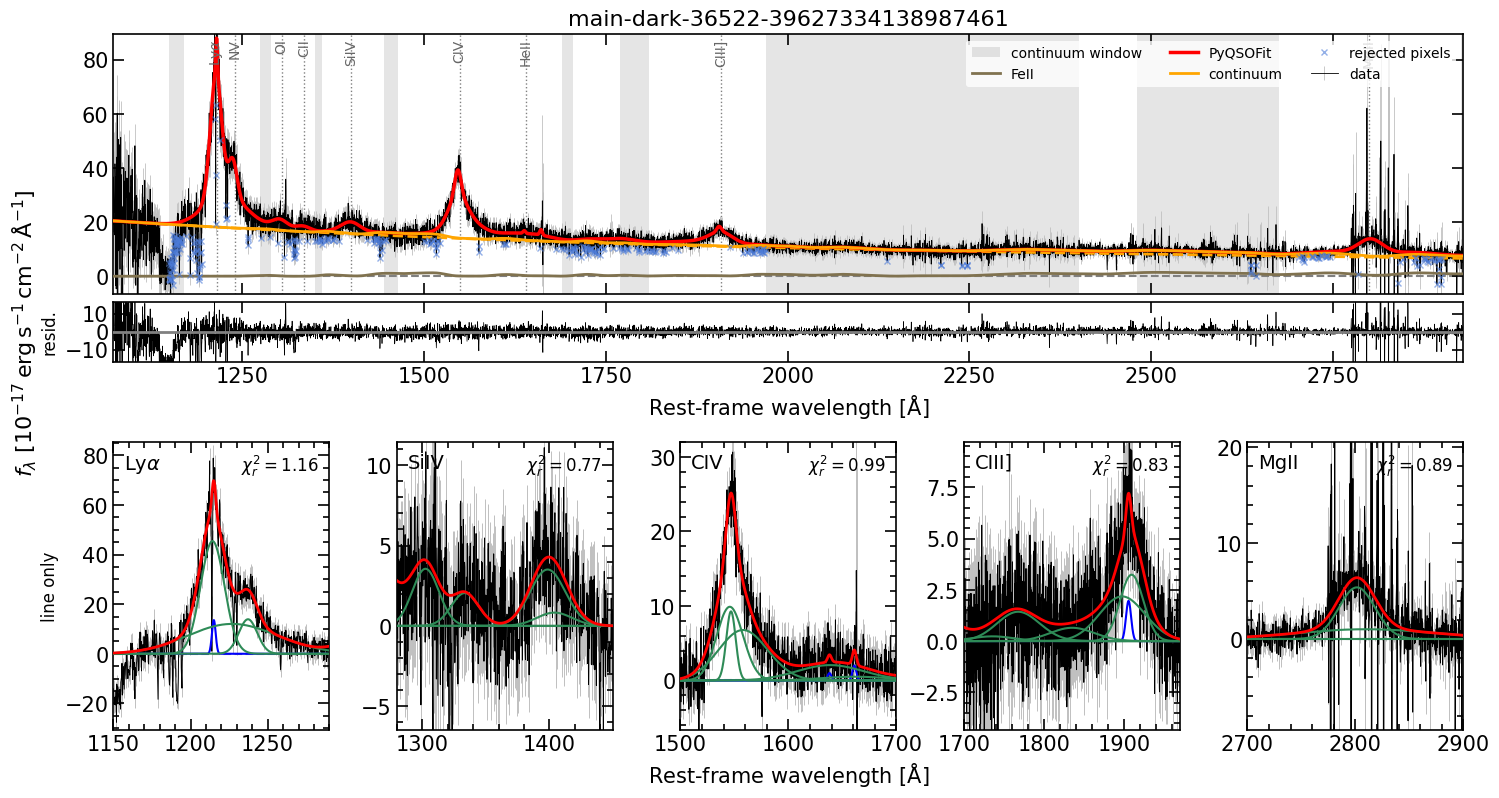

In [13]:
fig = plot_qa(op_data, op_data_spec, title=objid)
plt.show()

# 4. Low-redshift object with host-galaxy decomposition

For $z<1$ the host galaxy is removed first, by fitting the spectrum with quasar and galaxy PCA eigenspectra
(Ren et al. 2024). The continuum and lines are then fitted to the host-subtracted spectrum `flux_hostfree`.
Extension 1 then has these extra columns:

| Column | Description |
| --- | --- |
| `SN_host` | median S/N of the spectrum used in the decomposition |
| `rchi2_decomp` | reduced $\chi^2$ of the decomposition |
| `frac_host_4200`, `frac_host_5100` | host fraction of the total flux at 4200 / 5100 Å |
| `Dn4000` | $D_n4000$ of the host model |
| `sigma`, `sigma_err`, `v_off`, `v_off_err`, `rchi2_ppxf` | stellar kinematics fit (not used in this work) |
| `gal_par_0..4`, `qso_par_0..9` | coefficients of the galaxy and quasar eigenspectra |

`L4200` and `L5100` are measured on the host-subtracted spectrum (quasar only).

In [14]:
objid2 = 'sv1-dark-6872-39633211269056848'
op_data2, op_data_MC2, op_data_spec2 = read_op(f'./download/op_{objid2}.fits.gz')

print(op_data_spec2.names)
for name in ['redshift', 'SN_host', 'rchi2_decomp', 'frac_host_4200', 'frac_host_5100', 'Dn4000', 'L5100']:
    print(f'{name:16s} {op_data2[name][0]:.4f}')

['wave_prereduced', 'flux_prereduced', 'err_prereduced', 'wave_hostfree', 'flux_hostfree', 'err_hostfree', 'flux_pca_qso', 'flux_pca_host', 'wave_conti_rej_abs', 'wave_line_rej_abs']
redshift         0.3235
SN_host          16.0980
rchi2_decomp     71.3477
frac_host_4200   0.2131
frac_host_5100   0.2324
Dn4000           1.1818
L5100            44.6125


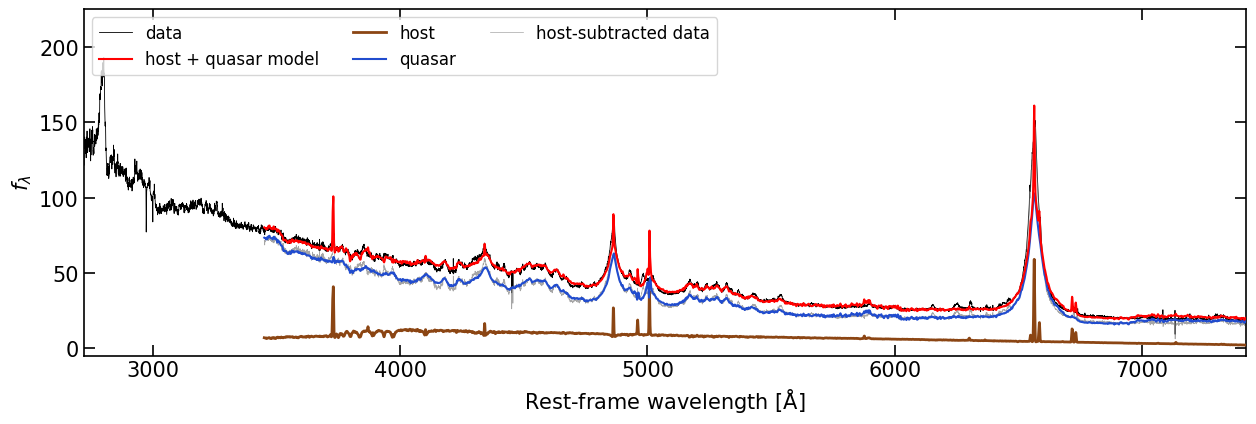

In [15]:
wave2, flux2, err2 = get_spectrum(op_data_spec2)                       # observed (host + quasar)
wave_hf, flux_hf, err_hf = get_spectrum(op_data_spec2, hostfree=True)  # host-subtracted
n = len(wave_hf)
host2 = op_data_spec2['flux_pca_host'][:n]
qso2 = op_data_spec2['flux_pca_qso'][:n]

fig, ax = plt.subplots(1, 1, figsize=(15, 4.5))
ax.plot(wave2, flux2, c='k', lw=0.6, label='data', zorder=1)
ax.plot(wave_hf, host2+qso2, c='red', lw=1.5, label='host + quasar model', zorder=4)
ax.plot(wave_hf, host2, c='saddlebrown', lw=2, label='host', zorder=3)
ax.plot(wave_hf, qso2, c='#214cce', lw=1.5, label='quasar', zorder=3)
ax.plot(wave_hf, flux_hf, c='grey', lw=0.5, alpha=0.7, label='host-subtracted data', zorder=2)
ax.legend(loc='upper left', ncol=3, fontsize=12)
ax.set_xlabel(r'Rest-frame wavelength [$\rm \AA$]')
ax.set_ylabel(r'$f_{\lambda}$')
ax.set_xlim(wave2.min(), wave2.max())
ax.set_ylim(-5, 1.25*np.percentile(flux2, 99.8))
plt.show()

In [16]:
for line in ['HBETA_BR', 'HALPHA_BR', 'NII6585']:
    get_line_prop(line, op_data2, op_data_MC2, op_data_spec2)

HBETA_BR
  Peak wavelength      4858.282 +-     0.111  [A]
  Flux                 2849.084 +-    71.783  [1e-17 erg/s/cm2]
  LogL                   42.991 +-     0.011  [erg/s]
  FWHM                 3544.373 +-    31.534  [km/s]
  EW                     96.924 +-     2.326  [A]
  Centroid             4862.365 +-     3.873  [A]
HALPHA_BR
  Peak wavelength      6563.711 +-     8.583  [A]
  Flux                 8267.769 +-  1476.502  [1e-17 erg/s/cm2]
  LogL                   43.453 +-     0.096  [erg/s]
  FWHM                 2327.685 +-   988.640  [km/s]
  EW                    461.434 +-    83.183  [A]
  Centroid             6563.019 +-     1.981  [A]
NII6585
  Peak wavelength      6589.523 +-     1.864  [A]
  Flux                   74.347 +-   224.589  [1e-17 erg/s/cm2]
  LogL                   41.407 +-     0.428  [erg/s]
  FWHM                  452.675 +-   481.632  [km/s]
  EW                      4.168 +-    12.587  [A]
  Centroid             6589.603 +-     1.818  [A]


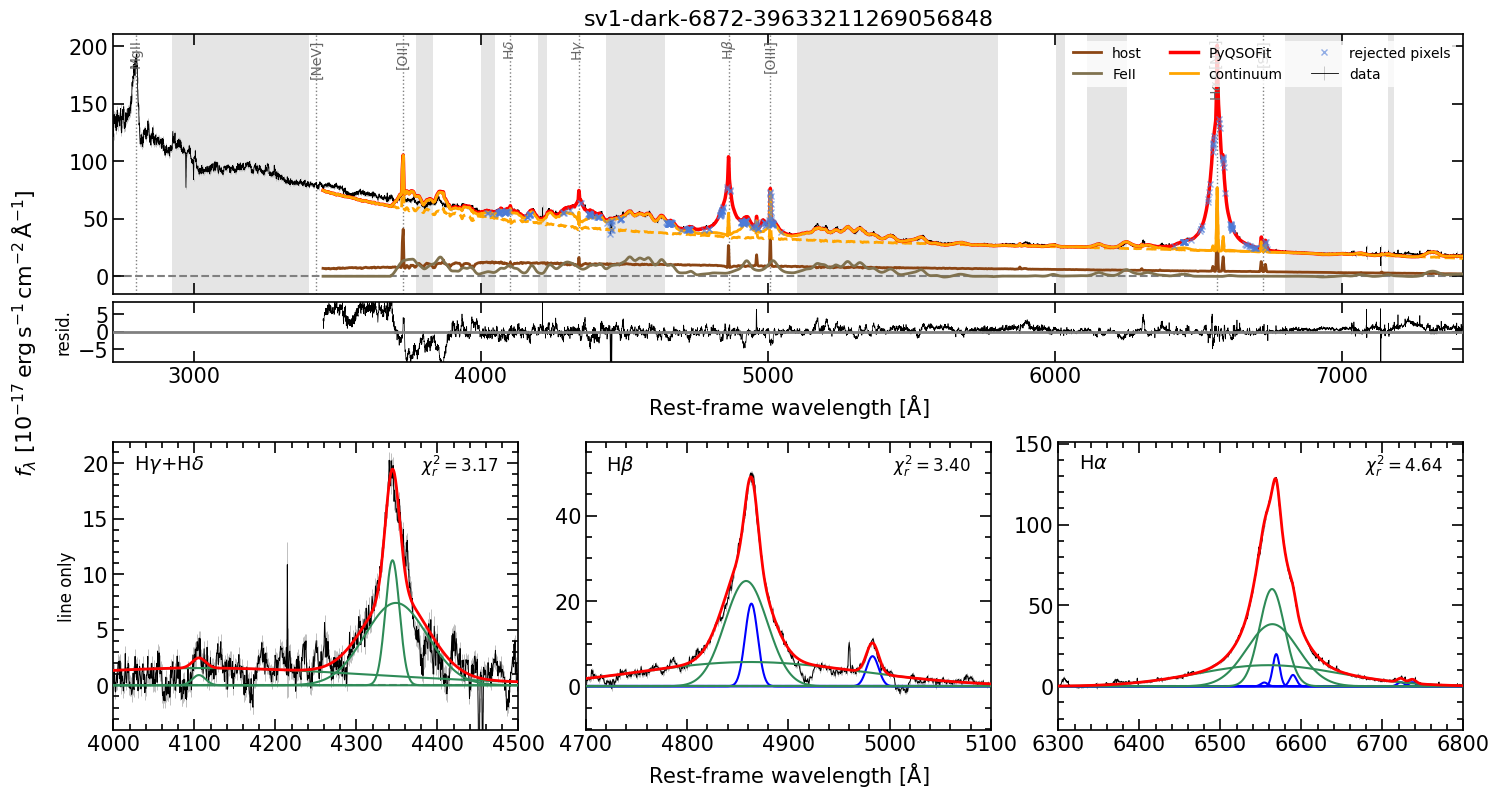

In [17]:
fig = plot_qa(op_data2, op_data_spec2, title=objid2)
plt.show()

# 5. Local fits of narrow and coronal lines

[NeV], [FeVII], [OII], CaII K (absorption), [FeXIV], [FeX], [SXII] and [FeXI] lines are not part of the complex
fits. Each is fitted in its own $\pm5000$ km/s window of the rest-frame spectrum (`flux_prereduced`, without host
subtraction) with a linear continuum plus one Gaussian. Here we use a third example,
`main-dark-19046-39627784217169648` ($z=0.37$), in which [OII], [NeV] $\lambda3426$ and [FeX] $\lambda6374$ are all
detected at high S/N. The model and the detection criteria are recorded in the header of extension 1:

In [18]:
objid3 = 'main-dark-19046-39627784217169648'
op_file3 = f'./download/op_{objid3}.fits.gz'
op_data3, op_data_MC3, op_data_spec3 = read_op(op_file3)
wave3, flux3, err3 = get_spectrum(op_data_spec3)

hdr = fits.getheader(op_file3, 1)
for key in ['LFMODEL', 'LFFRAME', 'LFFWHMMX', 'LFNBOOT', 'LFERRSRC', 'LFDETECT']:
    print(f'{key:9s}= {hdr[key]}')

LFMODEL  = linear continuum + 1 Gaussian
LFFRAME  = rest, Galactic-dereddened
LFFWHMMX = 2500.0
LFNBOOT  = 10
LFERRSRC = boot10 16-84 where dBIC>5 & S/N>=1, else cov (no _MC)
LFDETECT = dBIC>10 & S/N>=3 & unpinned & FWHM<=2500 & window fully covered & >20 good pix


For each local fit $k$ there are `loc_<k>_*` summary columns (as for the complexes, plus `loc_<k>_line_chi2_noline`,
the $\chi^2$ of the continuum-only fit), and for each line:

| Column | Description |
| --- | --- |
| `<comp>_PL_norm` | continuum flux density at the line wavelength (linear continuum, not a power law) |
| `<comp>_PL_slope` | continuum slope per 1000 km/s |
| `<line>_1_scale`, `<line>_1_centerwave`, `<line>_1_sigma` | the Gaussian, as for the complex fits (negative scale for absorption) |
| `<line>_1_detect` | 1 if the line is detected (criteria in `LFDETECT`) |

Bootstrap trials (`_MC` columns in extension 2) are saved only for lines with $\Delta$BIC > 5 and S/N ≥ 1;
otherwise the uncertainties are propagated from the `_err` columns. `get_local_line_prop` returns the same
six properties as the VAC columns.

In [19]:
for n in op_data3.names:
    if n.startswith('loc_') and n.endswith('_complex_name'):
        k = n[:-len('_complex_name')]
        print(f'{k:7s} {op_data3[n][0]:10s} npix={op_data3[k+"_npix"][0]:4d}  red_chi2={op_data3[k+"_line_red_chi2"][0]:.2f}')

loc_1   NeV3346    npix= 173  red_chi2=1.38
loc_2   NeV        npix= 176  red_chi2=1.33
loc_3   FeVII3586  npix= 185  red_chi2=1.56
loc_4   OII        npix= 192  red_chi2=1.29
loc_5   FeVII3759  npix= 194  red_chi2=21.84
loc_6   CaII       npix= 203  red_chi2=2.72
loc_7   FeXIV5303  npix= 260  red_chi2=1.65
loc_8   FeVII5721  npix= 295  red_chi2=3.92
loc_9   FeVII6087  npix= 310  red_chi2=1.23
loc_10  FeX6374    npix= 322  red_chi2=2.60


In [20]:
for line in ['OII3728', 'NEV3426', 'FEX6374']:
    prop, prop_err, detect = get_local_line_prop(line, op_data3, op_data_MC3)
    print('  detected:', bool(detect))

OII3728
  Peak wavelength      3727.190 +-     0.054  [A]
  Flux                  328.564 +-     4.639  [1e-17 erg/s/cm2]
  LogL                   42.198 +-     0.006  [erg/s]
  FWHM                  547.533 +-     9.971  [km/s]
  EW                      6.726 +-     0.097  [A]
  Centroid             3727.194 +-     0.054  [A]
  detected: True
NEV3426
  Peak wavelength      3425.896 +-     0.110  [A]
  Flux                  113.411 +-     4.240  [1e-17 erg/s/cm2]
  LogL                   41.736 +-     0.016  [erg/s]
  FWHM                  440.194 +-    27.039  [km/s]
  EW                      1.984 +-     0.072  [A]
  Centroid             3425.898 +-     0.110  [A]
  detected: True
FEX6374
  Peak wavelength      6377.622 +-     0.059  [A]
  Flux                   69.536 +-     2.196  [1e-17 erg/s/cm2]
  LogL                   41.523 +-     0.014  [erg/s]
  FWHM                  150.454 +-     3.371  [km/s]
  EW                      2.414 +-     0.081  [A]
  Centroid             6377.6

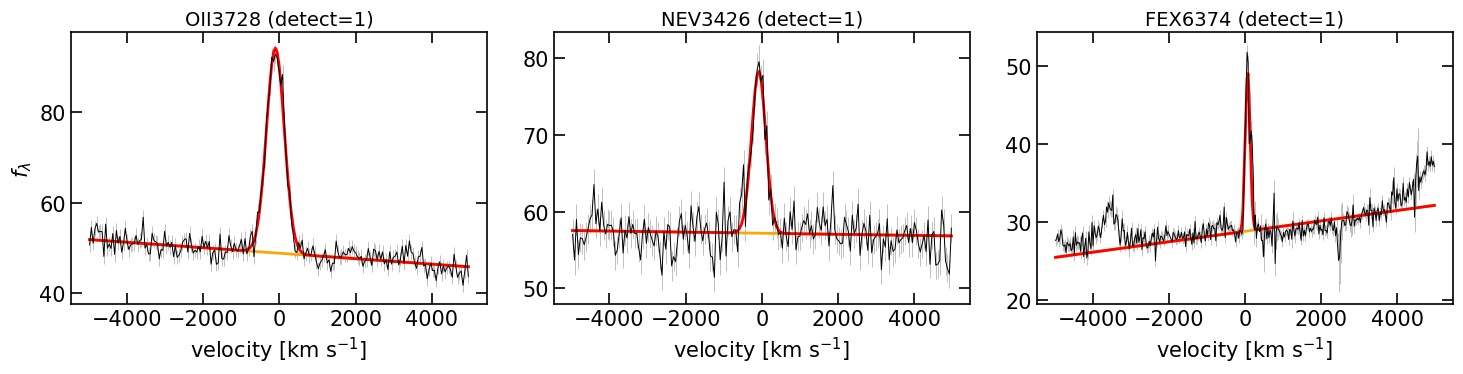

In [21]:
# plot the local fits
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, line in zip(axes, ['OII3728', 'NEV3426', 'FEX6374']):
    comp, gname, lam = LOCAL_LINES[line]
    v = (wave3/lam - 1)*C_KMS
    m = abs(v) < 5000
    pp = get_gauss(op_data3, [gname+'_1'], positive_only=False)
    cont = op_data3[comp+'_PL_norm'][0] + op_data3[comp+'_PL_slope'][0]*v[m]/1000.
    ax.errorbar(v[m], flux3[m], yerr=err3[m], color='k', ecolor='silver', lw=0.7)
    ax.plot(v[m], cont, c='orange', lw=2)
    ax.plot(v[m], cont + Manygauss(np.log(wave3[m]), pp), c='red', lw=2)
    ax.set_title(f'{line} (detect={op_data3[gname+"_1_detect"][0]})', fontsize=14)
    ax.set_xlabel(r'velocity [km s$^{-1}$]')
axes[0].set_ylabel(r'$f_{\lambda}$')
plt.tight_layout()
plt.show()